# Urban Land Cover Analysis Pipeline -- Phase 2 Progress Report

**Group H:** Nisarg Shah, Ansar Ur Rahman Mohammed

Digital Image Processing -- Course Project, Phase 2 (progress checkpoint), October 2026

Repository: https://github.com/nisarg-007/dip-urban-land-cover-pipeline

## 1. Project Objective

We are building a classical (non-machine-learning) image-processing pipeline that makes an urban aerial scene easier
to interpret for land-cover discrimination, so that roads, buildings, vegetation and water can be told apart and
measured. The pipeline corrects illumination and contrast so that shadowed regions are usable, enhances local
contrast, denoises and sharpens structural detail, separates coarse regions from fine detail in the frequency domain,
and extracts edges and corners (building outlines, road intersections) that a later segmentation step can build on.

In [1]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 100, "font.size": 9, "axes.titlesize": 9})
pd.set_option("display.precision", 3)
pd.set_option("display.width", 120)
# Tables render as real LaTeX tables in the PDF export
pd.set_option("styler.render.repr", "latex")
pd.set_option("styler.format.precision", 3)
pd.set_option("styler.latex.hrules", True)
pd.set_option("styler.format.escape", "latex")

DATA_PATH = os.path.join("data", "naip_raw.png")
color = cv2.imread(DATA_PATH, cv2.IMREAD_COLOR)
assert color is not None, f"could not read {DATA_PATH}"
gray = cv2.cvtColor(color, cv2.COLOR_BGR2GRAY)

# Zoom window used for close-up comparisons (tall-building shadows, I-45 ramps, parking lots)
CROP = (slice(380, 764), slice(300, 684))

# Tone bands used by several metrics below
shadow_mask = gray <= np.percentile(gray, 25)
bright_mask = gray >= np.percentile(gray, 75)


def rgb(im):
    return cv2.cvtColor(im, cv2.COLOR_BGR2RGB) if im.ndim == 3 else im


def show(images, titles, suptitle=None, cols=None, size=3.4, crop=False):
    cols = cols or len(images)
    rows = int(np.ceil(len(images) / cols))
    height = (size + 0.55) * rows + 0.4
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, height), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, im, t in zip(axes.ravel(), images, titles):
        im = im[CROP] if crop else im
        ax.imshow(rgb(im), cmap="gray" if im.ndim == 2 else None, vmin=0, vmax=255)
        ax.set_title(t)
    if suptitle:
        fig.suptitle(suptitle, fontsize=11, fontweight="bold")
    fig.tight_layout(rect=(0, 0, 1, 1 - 0.35 / height))
    plt.show()


def local_std_map(img, k=16):
    f = img.astype(np.float32)
    m = cv2.blur(f, (k, k))
    return np.sqrt(np.clip(cv2.blur(f * f, (k, k)) - m * m, 0, None))


def psnr(ref, img):
    mse = np.mean((ref.astype(np.float64) - img.astype(np.float64)) ** 2)
    return float("inf") if mse == 0 else 10 * np.log10(255.0 ** 2 / mse)


print("image size:", gray.shape[::-1], "| gray min/mean/max:", gray.min(), round(gray.mean(), 1), gray.max())

image size: (1024, 1024) | gray min/mean/max: 45 161.6 253


## 2. Dataset / Image Sample

**Source:** USDA **NAIP** (National Agriculture Imagery Program) 1 m/pixel true-color aerial orthoimagery, retrieved
from the USGS National Map NAIP ImageServer (the same NAIP holdings indexed by USGS EarthExplorer). NAIP is U.S.
Government public-domain data (credit: USDA Farm Production and Conservation Business Center / USGS).

**Scene:** a 1024 x 1024 px crop of downtown Houston, TX, at the I-45 (Pierce Elevated) / US-59 interchange, near the
George R. Brown Convention Center and Discovery Green. One frame contains high-rise buildings with long shadows, a
multi-level highway interchange, a street grid, parking lots, trees and lawns. It contains **no open water**: Buffalo
Bayou, named in our proposal, runs just north of this crop. The water class is therefore not tested in Phase 2 (see
Next Steps). Export request used:

```
https://imagery.nationalmap.gov/arcgis/rest/services/
    USGSNAIPImagery/ImageServer/exportImage
    ?bbox=-95.377495,29.748295,-95.366905,29.757515
    &bboxSR=4326&imageSR=4326&size=1024,1024&format=png&f=image
```

The image is saved in the repository as `data/naip_raw.png`. Because a 1024 px frame is small in print, most
parameter comparisons below are also shown on a 384 x 384 px zoom window (yellow box), which covers building shadows,
the highway ramps and parking lots.

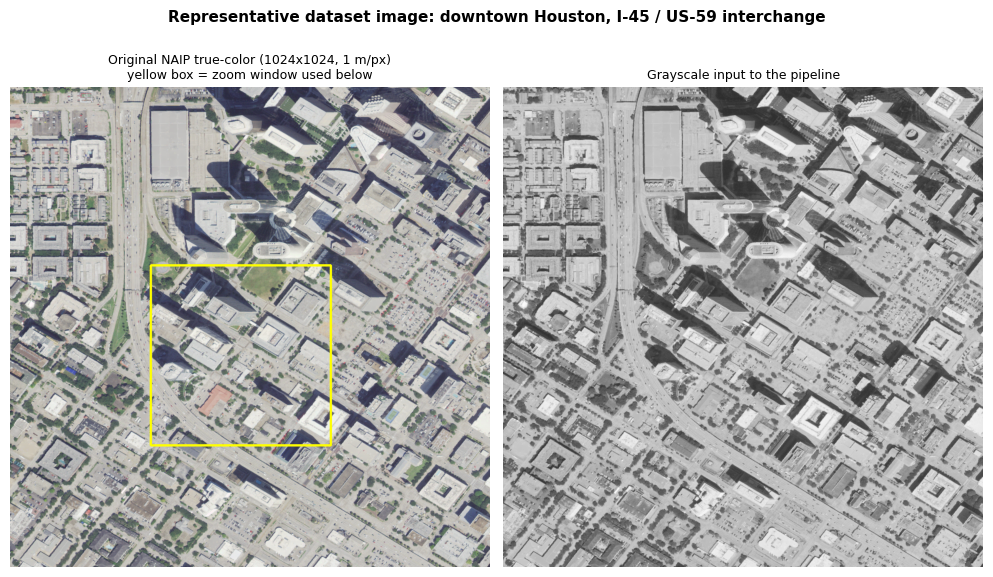

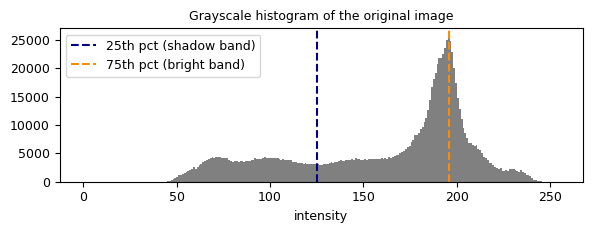

In [2]:
boxed = color.copy()
cv2.rectangle(boxed, (CROP[1].start, CROP[0].start), (CROP[1].stop, CROP[0].stop), (0, 255, 255), 4)
show([boxed, gray], ["Original NAIP true-color (1024x1024, 1 m/px)\nyellow box = zoom window used below",
                     "Grayscale input to the pipeline"],
     suptitle="Representative dataset image: downtown Houston, I-45 / US-59 interchange", size=5)

fig, ax = plt.subplots(figsize=(6, 2.4))
ax.hist(gray.ravel(), bins=256, range=(0, 255), color="gray")
ax.axvline(np.percentile(gray, 25), color="navy", ls="--", label="25th pct (shadow band)")
ax.axvline(np.percentile(gray, 75), color="darkorange", ls="--", label="75th pct (bright band)")
ax.set_title("Grayscale histogram of the original image"); ax.set_xlabel("intensity"); ax.legend()
fig.tight_layout(); plt.show()

## 3. Implemented Processing Stages

We implemented techniques from all five project categories: point processing, histogram processing, spatial
filtering, frequency-domain filtering, and edge & corner detection. Each stage shows the input, the output, a
parameter experiment, and a short analysis.

**Where the baselines come from.** Two kinds of earlier settings are compared against below:

- *Proposal (Phase 1 document):* the smoke-test values gamma = 1.4, median k = 5, FFT low-pass radius 60 px, CLAHE
  clip 2.5 / 8 x 8 tiles, Harris k = 0.04.
- *Repo baseline:* our first full script run after the proposal (`scripts/dip_pipeline.py`), which set the Canny
  thresholds and the Harris threshold (0.01 x max). The proposal called the Canny rule a "median-intensity
  heuristic"; the code actually uses the median of the *gradient magnitude*, which is the version tested here.

### 3.1 Point Processing -- Gamma Correction and Linear Contrast Stretch

**Gamma correction** uses $s = 255\,(r/255)^{1/\gamma}$, so $\gamma > 1$ brightens. Instead of picking $\gamma$ by eye, we
define "shadow" pixels as the darkest 25% of the scene and solve for the $\gamma$ that moves their mean to a mid-gray
target of 110: $\gamma = \ln(\bar r_{shadow}/255) / \ln(110/255)$. We compare it against no correction and two stronger values.

The local-contrast gain columns divide the mean local standard deviation (16 x 16 window) after correction by the
value before correction, separately for the darkest and brightest quartiles. A value below 1 means texture in that
band was flattened.

In [3]:
def gamma_correct(img, g):
    return np.clip(255.0 * np.power(img / 255.0, 1.0 / g), 0, 255).astype(np.uint8)

shadow_mean = float(gray[shadow_mask].mean())
TARGET = 110.0
gamma_auto = float(np.log(shadow_mean / 255.0) / np.log(TARGET / 255.0))

base_std = local_std_map(gray)
rows, gamma_imgs = [], {}
for g in [1.0, gamma_auto, 1.6, 2.2]:
    out = gamma_correct(gray, g)
    s = local_std_map(out)
    gamma_imgs[g] = out
    rows.append({"gamma": g,
                 "shadow mean": out[shadow_mask].mean(),
                 "bright mean": out[bright_mask].mean(),
                 "shadow local-contrast gain": s[shadow_mask].mean() / base_std[shadow_mask].mean(),
                 "bright local-contrast gain": s[bright_mask].mean() / base_std[bright_mask].mean()})
gamma_table = pd.DataFrame(rows)
print(f"shadow-quartile mean before correction = {shadow_mean:.1f}; solved gamma = {gamma_auto:.3f}")
gamma_table

shadow-quartile mean before correction = 89.5; solved gamma = 1.245


,gamma,shadow mean,bright mean,shadow local-contrast gain,bright local-contrast gain
0,1.000,89.495,207.126,1.000,1.000
1,1.245,109.106,215.269,0.919,0.884
2,1.600,131.221,223.416,0.811,0.753
3,2.200,156.918,231.323,0.667,0.596


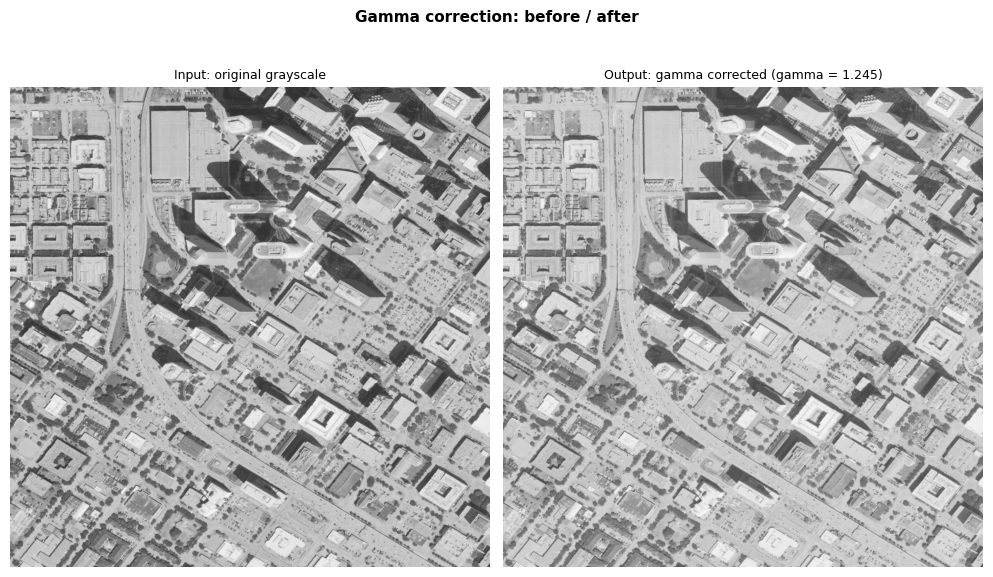

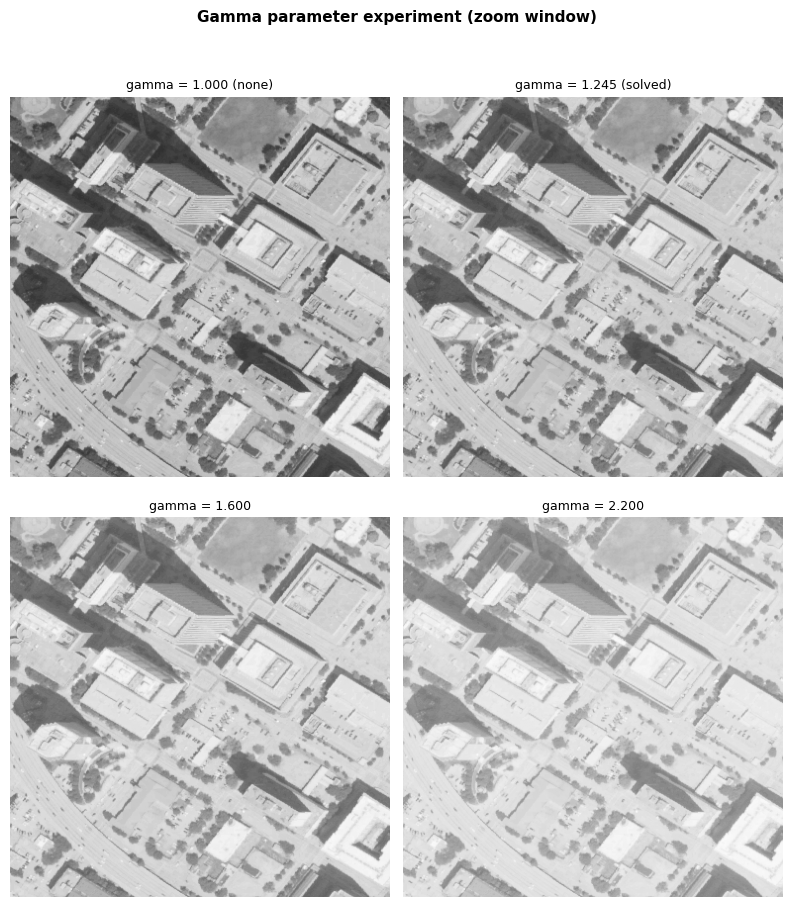

In [4]:
gamma_img = gamma_imgs[gamma_auto]
show([gray, gamma_img], ["Input: original grayscale", f"Output: gamma corrected (gamma = {gamma_auto:.3f})"],
     suptitle="Gamma correction: before / after", size=5)
show([gamma_imgs[g] for g in gamma_imgs],
     [f"gamma = {g:.3f}" + (" (none)" if g == 1.0 else " (solved)" if g == gamma_auto else "") for g in gamma_imgs],
     cols=2, size=4, suptitle="Gamma parameter experiment (zoom window)", crop=True)

**Parameter result.** The solved value $\gamma = 1.245$ moves the shadow mean from 89.5 to 109.1, within 1% of the
target of 110. $\gamma = 1.6$ and $2.2$ overshoot (131 and 157) and lighten the image visibly. They also flatten
texture: bright-band contrast gain drops to 0.75 and 0.60, so light roofs and pavement start to wash out. The solved
$\gamma$ worked best because it is the smallest correction that reaches the target, so it costs the least highlight
contrast.

**Analysis.**

- *What changed:* the whole image got brighter. The biggest change is in shadowed building faces and tree canopy,
  which move from near-black into the mid-tones.
- *Did it help:* partly. Shadowed areas are now in a usable intensity range, but gamma alone did **not** increase local
  contrast in the shadows (gain 0.92). It shifts brightness; it does not add detail. The stretch and CLAHE stages
  below supply the contrast.
- *Unwanted effects:* highlights are compressed (bright-band gain 0.88), so bright rooftops lose some texture.
- *Decision:* **keep**, using the solved $\gamma$ rather than a fixed value. Its main job is to move shadows into a
  range where the following contrast steps can work.

In [5]:
rows = [{"percentile clip": "none (input)", "input low": gamma_img.min(), "input high": gamma_img.max(),
         "% pixels saturated (0 or 255)": 100 * np.mean((gamma_img == 0) | (gamma_img == 255)),
         "global std": gamma_img.std(), "mean local std": local_std_map(gamma_img).mean()}]
stretch_imgs = {}
for lo, hi in [(0, 100), (2, 98), (5, 95)]:
    a, b = np.percentile(gamma_img, [lo, hi])
    out = np.clip((gamma_img.astype(np.float64) - a) * 255.0 / max(b - a, 1e-6), 0, 255).astype(np.uint8)
    stretch_imgs[(lo, hi)] = out
    rows.append({"percentile clip": f"{lo}/{hi}", "input low": a, "input high": b,
                 "% pixels saturated (0 or 255)": 100 * np.mean((out == 0) | (out == 255)),
                 "global std": out.std(),
                 "mean local std": local_std_map(out).mean()})
stretch_table = pd.DataFrame(rows)
stretched = stretch_imgs[(2, 98)]
stretch_table

,percentile clip,input low,input high,% pixels saturated (0 or 255),global std,mean local std
0,none (input),63.0,253.0,0.000,43.236,26.665
1,0/100,63.0,253.0,0.006,58.010,35.775
2,2/98,80.0,233.0,4.518,71.385,44.157
3,5/95,89.0,224.0,10.133,79.009,49.191


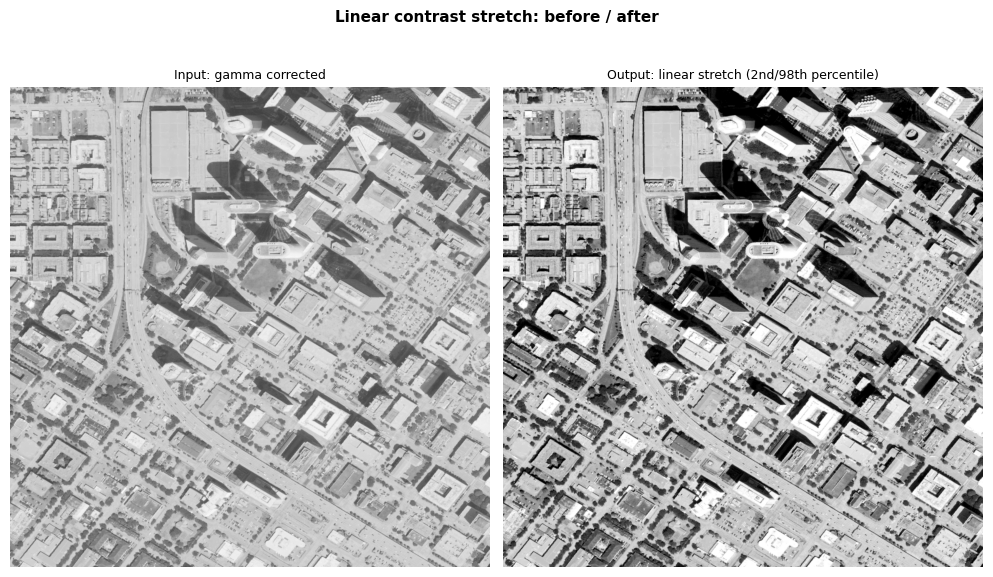

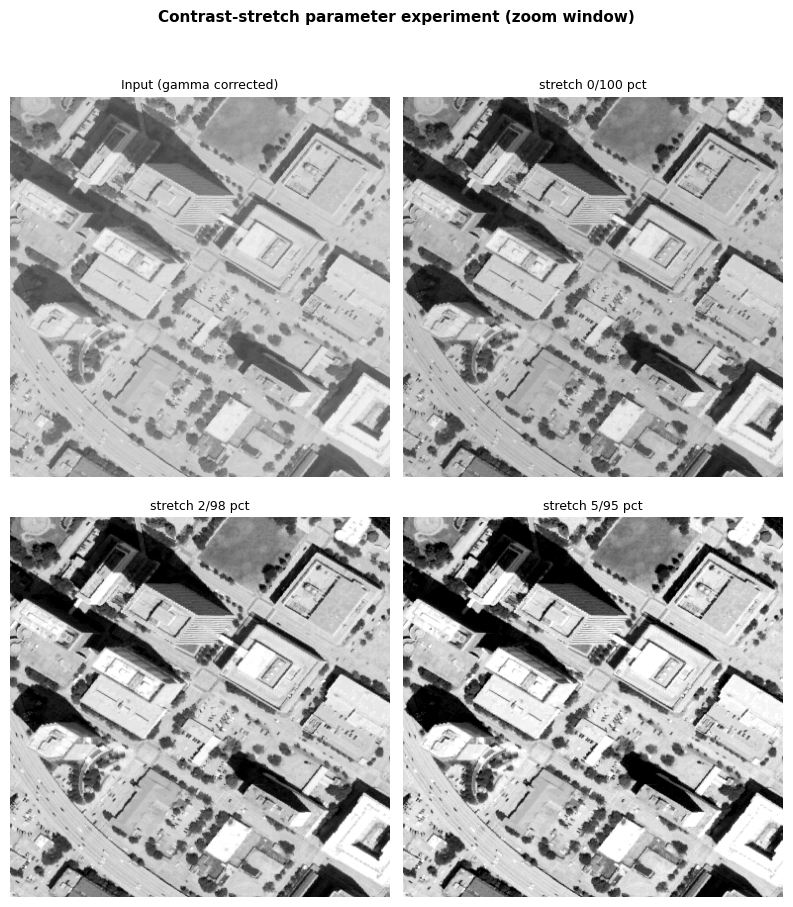

In [6]:
show([gamma_img, stretched], ["Input: gamma corrected", "Output: linear stretch (2nd/98th percentile)"],
     suptitle="Linear contrast stretch: before / after", size=5)
show([gamma_img] + list(stretch_imgs.values()),
     ["Input (gamma corrected)"] + [f"stretch {k[0]}/{k[1]} pct" for k in stretch_imgs],
     cols=2, size=4, suptitle="Contrast-stretch parameter experiment (zoom window)", crop=True)

**Parameter result.** We compared min/max stretching (0/100 percentile), a 2/98 percentile clip, and a 5/95 percentile
clip, starting from a mean local std of 26.7. Min/max raises it to 35.8 (+34%) but is limited by a few extreme pixels
at 63 and 253. The 2/98 clip ignores those outliers and raises local std to 44.2 (+66%) while saturating only 4.5% of
pixels. The 5/95 clip gives more contrast (49.2) but saturates 10% of the image, which turns the brightest roofs and
deepest shadows pure white and black. **2/98 worked best**: most of the gain, with a small, controlled amount of
clipping.

**Analysis.**

- *What changed:* the 80-233 intensity band that holds 96% of the pixels now covers the full 0-255 range, so pavement,
  roofs and lawns are spread further apart in tone.
- *Did it help:* yes. Global contrast (std 43.2 to 71.4) and local contrast (26.7 to 44.2) both increase.
- *Unwanted effects:* 4.5% of pixels are clipped, mostly specular roofs and the darkest shadow cores.
- *Decision:* **keep** with the 2/98 clip.

### 3.2 Histogram Processing -- CLAHE vs. Global Histogram Equalization

We vary the CLAHE clip limit (1.5, 2.5, 4.0) and tile grid (4 x 4, 8 x 8, 16 x 16), and compare against global
histogram equalization (HE). Three measures are reported, each relative to the stretched input:

- **gain dark / gain bright:** local-contrast gain in the darkest and brightest quartiles.
- **balance (dark/bright):** the ratio of those two gains. A value of 1.0 means both bands improved equally.
- **gain in flat regions:** local-contrast gain in the 20% smoothest neighborhoods (bare roofs and pavement). Gain
  there is mostly amplified noise and texture, so lower is better.

In [7]:
pre_std = local_std_map(stretched)
# "Flat" pixels = the 20% smoothest neighbourhoods (bare roofs, pavement). Contrast gain
# there is mostly amplified noise/texture, so it is tracked as an unwanted-effect metric.
flat_mask = pre_std <= np.percentile(pre_std, 20)

def he_metrics(name, out):
    s = local_std_map(out)
    gd = s[shadow_mask].mean() / pre_std[shadow_mask].mean()
    gb = s[bright_mask].mean() / pre_std[bright_mask].mean()
    return {"method": name, "mean local std": s.mean(), "gain dark": gd, "gain bright": gb,
            "balance (dark/bright)": gd / gb, "gain in flat regions": s[flat_mask].mean() / pre_std[flat_mask].mean()}

he_imgs = {"global HE": cv2.equalizeHist(stretched)}
for clip, tile in [(1.5, 8), (2.5, 8), (4.0, 8), (2.5, 4), (2.5, 16)]:
    he_imgs[f"CLAHE clip={clip}, tile={tile}"] = cv2.createCLAHE(clipLimit=clip, tileGridSize=(tile, tile)).apply(stretched)
clahe_table = pd.DataFrame([he_metrics(k, v) for k, v in he_imgs.items()])
clahe_img = he_imgs["CLAHE clip=2.5, tile=8"]
clahe_table

,method,mean local std,gain dark,gain bright,balance (dark/bright),gain in flat regions
0,global HE,50.091,0.909,1.370,0.663,1.800
1,"CLAHE clip=1.5, tile=8",46.605,1.016,1.081,0.940,1.188
2,"CLAHE clip=2.5, tile=8",47.660,0.999,1.145,0.873,1.370
3,"CLAHE clip=4.0, tile=8",48.913,0.978,1.223,0.799,1.589
4,"CLAHE clip=2.5, tile=4",46.879,0.977,1.138,0.859,1.324
5,"CLAHE clip=2.5, tile=16",48.881,1.032,1.155,0.894,1.432


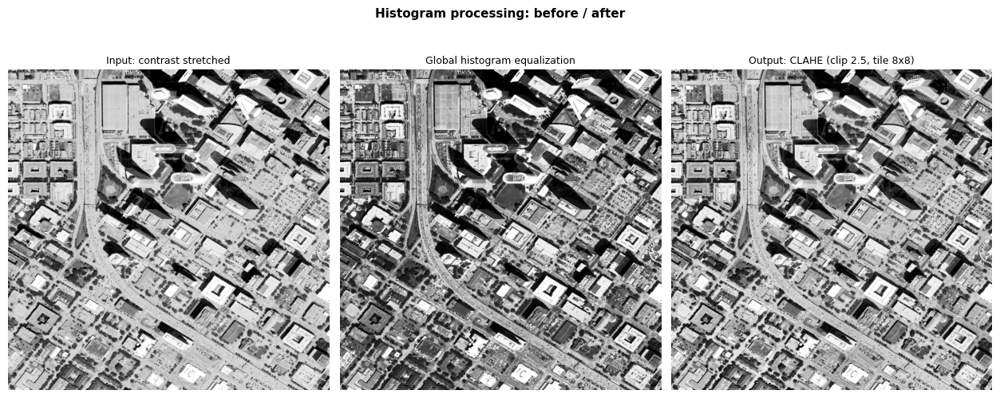

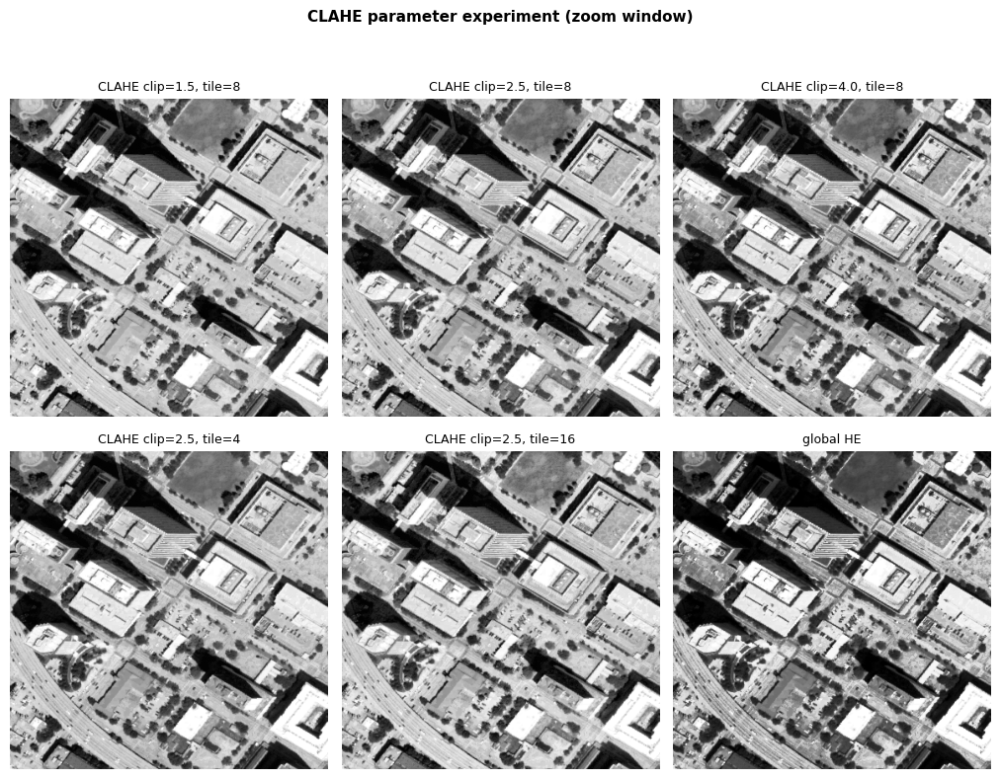

In [8]:
show([stretched, he_imgs["global HE"], clahe_img],
     ["Input: contrast stretched", "Global histogram equalization", "Output: CLAHE (clip 2.5, tile 8x8)"],
     suptitle="Histogram processing: before / after", size=4.2)
keys = ["CLAHE clip=1.5, tile=8", "CLAHE clip=2.5, tile=8", "CLAHE clip=4.0, tile=8",
        "CLAHE clip=2.5, tile=4", "CLAHE clip=2.5, tile=16", "global HE"]
show([he_imgs[k] for k in keys], keys, cols=3, suptitle="CLAHE parameter experiment (zoom window)", crop=True)

**Parameter result.** Global HE has the highest overall local contrast (50.1), but it is the most unbalanced method
(0.66). It *reduces* contrast in shadows (gain 0.91) while boosting bright areas by 1.37x, and it amplifies flat
regions the most (1.80x), which shows up as grainy roofs in the zoom window. All CLAHE settings are more balanced.
Raising the clip limit from 1.5 to 4.0 trades balance (0.94 down to 0.80) and noise (1.19x up to 1.59x) for a little
more contrast (46.6 up to 48.9). Tile size matters less: 4 x 4 gives slightly less contrast (46.9), and 16 x 16 gives
more contrast (48.9) but amplifies flat regions more (1.43x).

**Which setting worked better:** on this table alone, clip 1.5 is best: the most balanced (0.94) and the least noise
amplification in flat regions (1.19x). Clip 2.5 (the proposal value) gives a little more contrast. Because the real
purpose of CLAHE here is to feed edge detection, we re-ran the full downstream chain (sharpen, blur, Canny) with clip
1.5, 2.0 and 2.5 in Section 3.5. The edge maps came out almost the same, with 2.5 slightly ahead, so we keep
**clip 2.5, tile 8 x 8**.

**Analysis.**

- *What changed:* texture on mid-gray pavement and bright roofs became more visible, and building outlines stand out
  more from their surroundings.
- *Did it help:* partly. CLAHE raises bright-band local contrast by 1.14x and leaves shadow contrast unchanged
  (0.999x). It does **not** add contrast in the shadows, but unlike global HE it does not take any away (global HE
  drops shadow contrast to 0.91x). That is the advantage over global HE on this mixed scene.
- *Unwanted effects:* flat roofs and lots get grainier (1.37x local-contrast gain in flat regions).
- *Decision:* **keep** at clip 2.5. Lowering the clip limit improves the balance metric but did not improve the
  downstream edges.

### 3.3 Spatial Filtering -- Median Filtering and Laplacian Sharpening

**Median filtering.** The NAIP crop has almost no impulse noise, so to test the filter properly we add 2% synthetic
salt-and-pepper noise (fixed random seed) to the CLAHE output. We then compare median kernels k = 3, 5, 7 and a 3 x 3
mean filter against the clean image. We measure PSNR and the correlation between Laplacian edge maps (how much fine
edge structure survives). We also apply k = 3 to the *real, un-noised* image to see what the filter costs when no
noise is present.

In [9]:
rng = np.random.default_rng(0)
noisy = clahe_img.copy()
n = int(0.02 * noisy.size)
ys, xs = rng.integers(0, noisy.shape[0], n), rng.integers(0, noisy.shape[1], n)
noisy[ys[: n // 2], xs[: n // 2]] = 255
noisy[ys[n // 2:], xs[n // 2:]] = 0

lap_clean = cv2.Laplacian(clahe_img, cv2.CV_32F)
def edge_corr(img):
    return float(np.corrcoef(lap_clean.ravel(), cv2.Laplacian(img, cv2.CV_32F).ravel())[0, 1])

den_imgs = {"noisy input": noisy,
            "median k=3": cv2.medianBlur(noisy, 3),
            "median k=5": cv2.medianBlur(noisy, 5),
            "median k=7": cv2.medianBlur(noisy, 7),
            "mean (box) k=3": cv2.blur(noisy, (3, 3))}
median_table = pd.DataFrame([{"filter": k, "PSNR vs clean (dB)": psnr(clahe_img, v),
                              "edge correlation vs clean": edge_corr(v)} for k, v in den_imgs.items()])

# Cost of the median filter on the real (un-noised) image
med_real = cv2.medianBlur(clahe_img, 3)
print(f"median k=3 on the REAL clean image: PSNR vs unfiltered = {psnr(clahe_img, med_real):.1f} dB, "
      f"edge correlation = {edge_corr(med_real):.3f}")
median_table

median k=3 on the REAL clean image: PSNR vs unfiltered = 26.5 dB, edge correlation = 0.613


,filter,PSNR vs clean (dB),edge correlation vs clean
0,noisy input,21.768,0.505
1,median k=3,26.193,0.593
2,median k=5,22.235,0.381
3,median k=7,20.190,0.274
4,mean (box) k=3,23.804,0.358


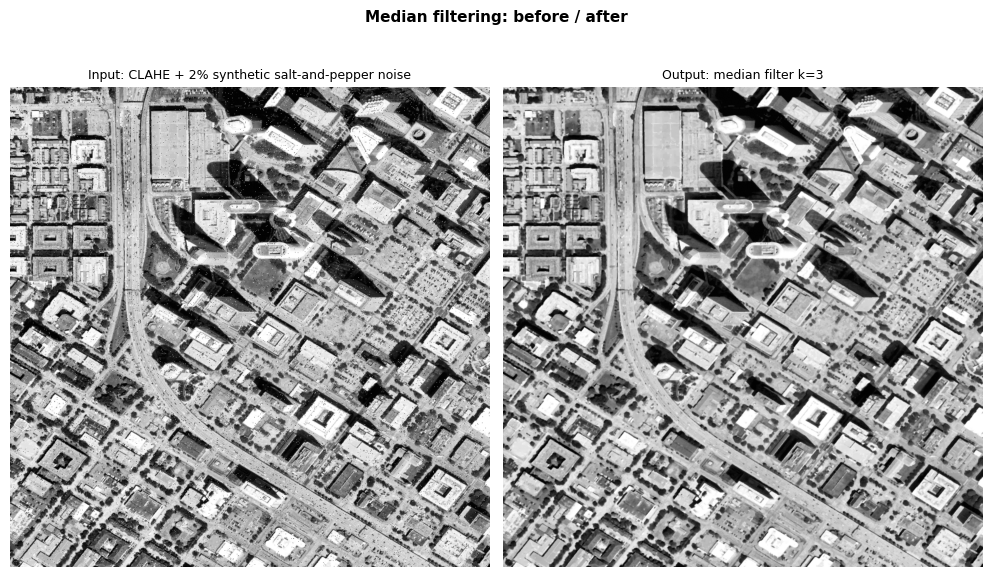

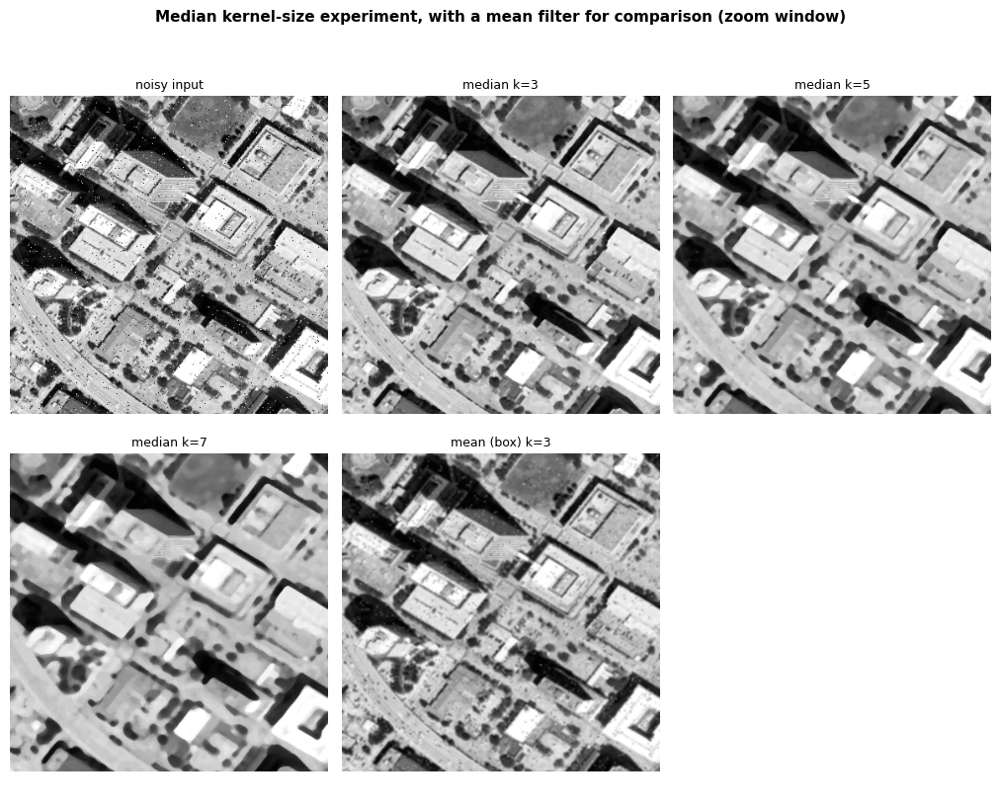

In [10]:
show([noisy, den_imgs["median k=3"]], ["Input: CLAHE + 2% synthetic salt-and-pepper noise", "Output: median filter k=3"],
     suptitle="Median filtering: before / after", size=5)
show(list(den_imgs.values()), list(den_imgs.keys()), cols=3, size=3.4,
     suptitle="Median kernel-size experiment, with a mean filter for comparison (zoom window)", crop=True)

**Parameter result.** **k = 3 worked best**: PSNR rises from 21.8 to 26.2 dB and edge correlation from 0.51 to 0.59.
Larger kernels remove the noise too, but they blur away real detail. k = 5 is barely better than the noisy input on
PSNR (22.2 vs. 21.8 dB), and k = 7 is worse (20.2 dB). On edge correlation, both are worse than the noisy input
(0.38 and 0.27 vs. 0.51). In the zoom window, cars, lot striping and thin ramps disappear at k = 7.
The 3 x 3 mean filter scores lower on both measures (23.8 dB and 0.36) because it smears the impulses into gray
blotches instead of removing them. This confirms that the median filter suits this kind of noise.

**Analysis.**

- *What changed:* the impulse noise is removed almost completely at k = 3.
- *Did it help:* yes for impulse noise. However, on the **real** image (which has no impulse noise), the k = 3 output
  measures only 26.5 dB PSNR against the unfiltered image and keeps only 0.61 edge correlation. It removes real
  detail such as cars and lot markings without removing any noise.
- *Unwanted effects:* loss of small, real structures, which gets worse quickly at larger kernel sizes.
- *Decision:* **modify**. We will use the median filter only when a scene actually has impulse noise or speckle, and
  **remove** it from the default chain for this clean NAIP scene. Smoothing before edge detection is handled better by
  a Gaussian blur (Section 3.5).

**Laplacian sharpening** computes $g = f - w\,\nabla^2 f$ on the CLAHE output. We tested weights from 0.03 to 0.6 and
measured the fraction of hard-clipped (0 or 255) pixels, which indicates overshoot and ringing. We also report the
mean absolute Laplacian as a "detail energy" check. That figure uses the same Laplacian operator as the sharpening
step, so it rises by construction as $w$ increases; the clipping budget is the actual selection rule.

In [11]:
lap = cv2.Laplacian(clahe_img, cv2.CV_64F, ksize=3)
rows, sharp_imgs = [], {}
for w in [0.03, 0.05, 0.1, 0.2, 0.6]:
    out = np.clip(clahe_img.astype(np.float64) - w * lap, 0, 255).astype(np.uint8)
    sharp_imgs[w] = out
    rows.append({"weight": w, "% pixels clipped (0/255)": 100 * np.mean((out == 0) | (out == 255)),
                 "mean |Laplacian| (detail energy)": np.mean(np.abs(cv2.Laplacian(out, cv2.CV_64F, ksize=3)))})
sharpen_table = pd.DataFrame(rows)
print(f"unsharpened CLAHE: {100 * np.mean((clahe_img == 0) | (clahe_img == 255)):.1f}% clipped, "
      f"detail energy {np.mean(np.abs(lap)):.1f}")
sharp = sharp_imgs[0.05]
sharpen_table

unsharpened CLAHE: 2.3% clipped, detail energy 105.3


,weight,% pixels clipped (0/255),mean |Laplacian| (detail energy)
0,0.03,3.450,131.618
1,0.05,4.586,149.023
2,0.10,7.848,190.934
3,0.20,14.727,263.669
4,0.60,35.766,444.294


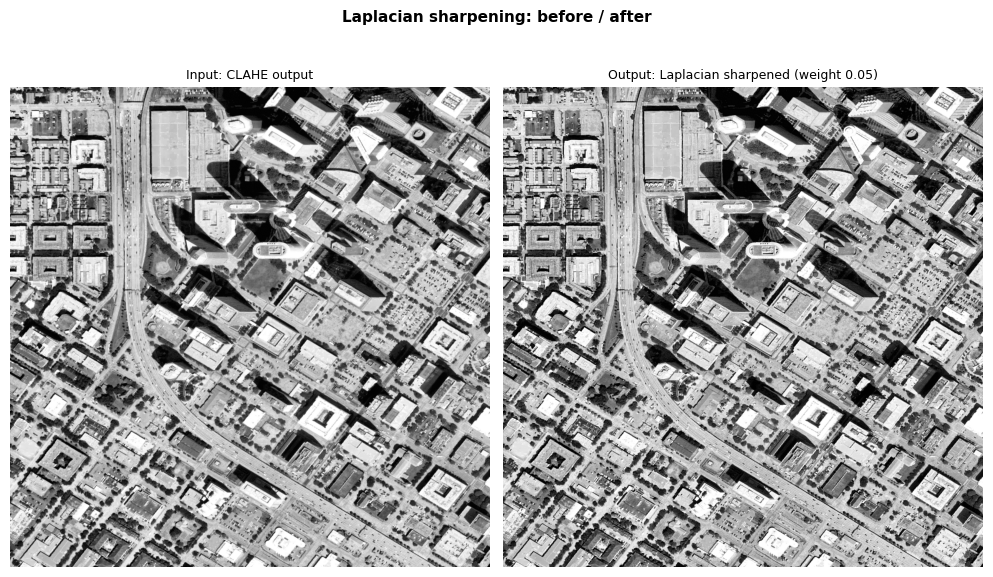

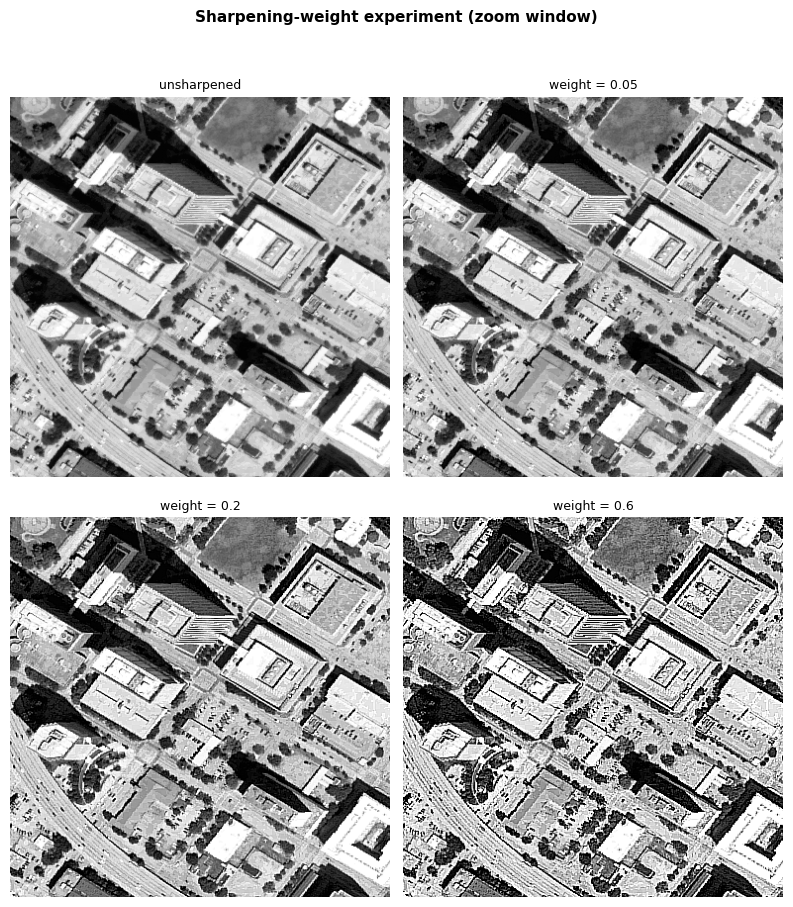

In [12]:
show([clahe_img, sharp], ["Input: CLAHE output", "Output: Laplacian sharpened (weight 0.05)"],
     suptitle="Laplacian sharpening: before / after", size=5)
show([clahe_img] + [sharp_imgs[w] for w in [0.05, 0.2, 0.6]],
     ["unsharpened"] + [f"weight = {w}" for w in [0.05, 0.2, 0.6]],
     cols=2, size=4, suptitle="Sharpening-weight experiment (zoom window)", crop=True)

**Parameter result.** Detail energy rises steadily with $w$, and so does clipping: 3.5% at 0.03, 4.6% at 0.05, 7.8% at
0.1, 14.7% at 0.2 and 35.8% at 0.6. With a 5% clipping budget, **$w = 0.05$ is the strongest setting we can use**.
It raises the Laplacian energy from 105 to 149 (+42%), as expected from using the same operator that does the
sharpening. At $w = 0.2$ and above, the zoom window shows bright and dark halos around every roof edge and car, and
pavement turns noisy.

**Analysis.**

- *What changed:* roof edges, curbs and ramp boundaries look crisper.
- *Did it help:* yes for visual interpretation. For edge detection the effect is mixed, because sharpening also
  amplifies texture and contributes to the overly dense repo-baseline Canny result (Section 3.5).
- *Unwanted effects:* halos and noise amplification at higher weights; even at 0.05, about 2.3 percentage points of
  extra pixels are clipped.
- *Decision:* **keep at w = 0.05** for the enhanced visual output, but always follow it with a Gaussian blur before
  edge and corner detection.

### 3.4 Frequency-Domain Filtering -- FFT Low-Pass / High-Pass

We take the 2-D FFT of the CLAHE output. Our first cut-off rule came from the image's own radial power spectrum: the
smallest radius that contains 90% of the AC power, excluding the DC term (the image mean, which would otherwise
satisfy any threshold at r = 0). We compare ideal (hard-cutoff) low-pass filters at r = 60 (the proposal value) and at
that 90% radius, with **Gaussian** low-pass filters $H = e^{-D^2/2D_0^2}$ at $D_0$ = 15, 30, 60 and the 90% radius.

Each filter is scored three ways:

- **% AC power kept.**
- **PSNR against the input.** This rewards weak filtering, so on its own it would always pick the largest cut-off.
- **% local contrast removed** (mean 16 x 16 local std, before vs. after). This measures how uniform the regions
  become, which is what a region map for segmentation needs.

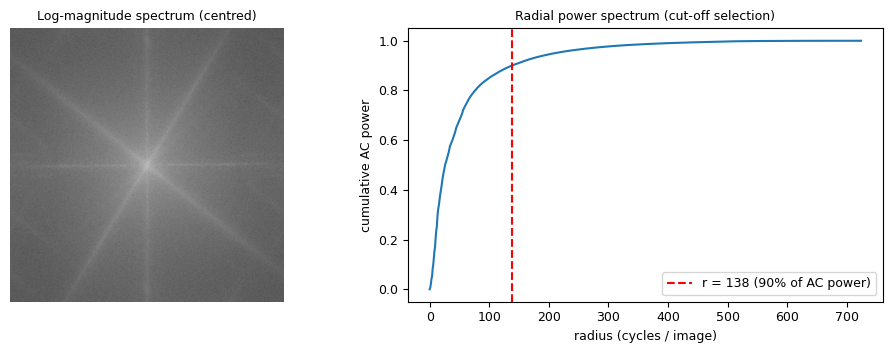

,low-pass filter,% AC power kept,PSNR vs input (dB),% local contrast removed
0,ideal r=60,73.574,16.755,32.298
1,ideal r=138,89.905,20.945,12.423
2,Gaussian D0=15,25.217,13.465,81.354
3,Gaussian D0=30,44.449,15.443,63.207
4,Gaussian D0=60,64.154,18.306,40.819
5,Gaussian D0=138,82.910,23.074,19.217


In [13]:
F = np.fft.fftshift(np.fft.fft2(clahe_img.astype(np.float64)))
h, w = clahe_img.shape
cy, cx = h // 2, w // 2
Y, X = np.ogrid[:h, :w]
D = np.sqrt((X - cx) ** 2 + (Y - cy) ** 2)

power = np.abs(F) ** 2
radial = np.bincount(D.astype(int).ravel(), weights=power.ravel())
radial[0] = 0.0                       # exclude DC (image mean), otherwise r=0 already holds most power
cum = np.cumsum(radial) / radial.sum()
r90 = int(np.searchsorted(cum, 0.90))

def inv(spec):
    return np.real(np.fft.ifft2(np.fft.ifftshift(spec)))

def gaussian_lp(d0):
    return np.exp(-(D ** 2) / (2.0 * d0 ** 2))

def percentile_stretch(x, lo=1, hi=99):
    a, b = np.percentile(x, [lo, hi])
    return np.clip((x - a) * 255.0 / (b - a), 0, 255).astype(np.uint8)

# Region uniformity: how much of the input's local contrast (16x16 std) the low-pass removes.
# PSNR alone favours the weakest filter, so both are reported.
input_local_std = local_std_map(clahe_img).mean()
lp_imgs, rows = {}, []
for name, H in [("ideal r=60", (D <= 60).astype(float)),
                (f"ideal r={r90}", (D <= r90).astype(float)),
                ("Gaussian D0=15", gaussian_lp(15)),
                ("Gaussian D0=30", gaussian_lp(30)),
                ("Gaussian D0=60", gaussian_lp(60)),
                (f"Gaussian D0={r90}", gaussian_lp(r90))]:
    out = np.clip(inv(F * H), 0, 255).astype(np.uint8)
    lp_imgs[name] = out
    ac = (power * H ** 2).copy(); ac[cy, cx] = 0
    rows.append({"low-pass filter": name, "% AC power kept": 100 * ac.sum() / (power.sum() - power[cy, cx]),
                 "PSNR vs input (dB)": psnr(clahe_img, out),
                 "% local contrast removed": 100 * (1 - local_std_map(out).mean() / input_local_std)})
fft_table = pd.DataFrame(rows)

D0 = 30
lp_img = lp_imgs[f"Gaussian D0={D0}"]
hp_img = percentile_stretch(inv(F * (1 - gaussian_lp(D0))))
hp_img_r90 = percentile_stretch(inv(F * (1 - gaussian_lp(r90))))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].imshow(np.log1p(np.abs(F)), cmap="gray"); axes[0].set_title("Log-magnitude spectrum (centred)"); axes[0].axis("off")
axes[1].plot(cum); axes[1].axvline(r90, color="r", ls="--", label=f"r = {r90} (90% of AC power)")
axes[1].set_xlabel("radius (cycles / image)"); axes[1].set_ylabel("cumulative AC power"); axes[1].legend()
axes[1].set_title("Radial power spectrum (cut-off selection)")
fig.tight_layout(); plt.show()
fft_table

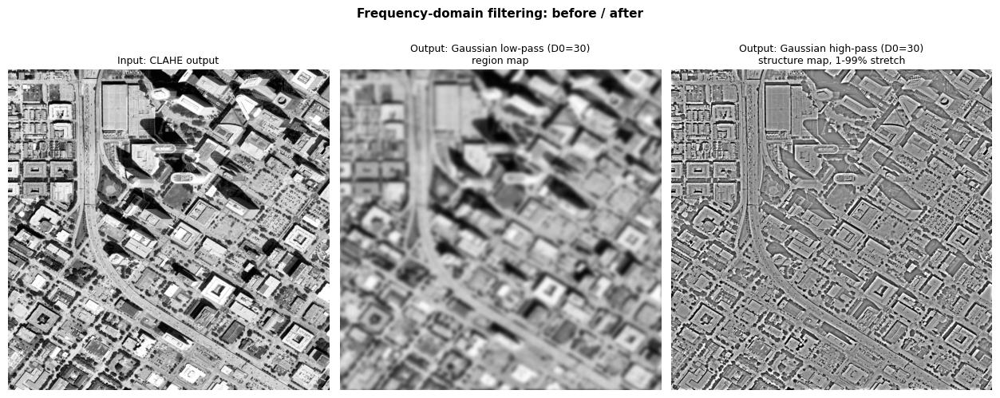

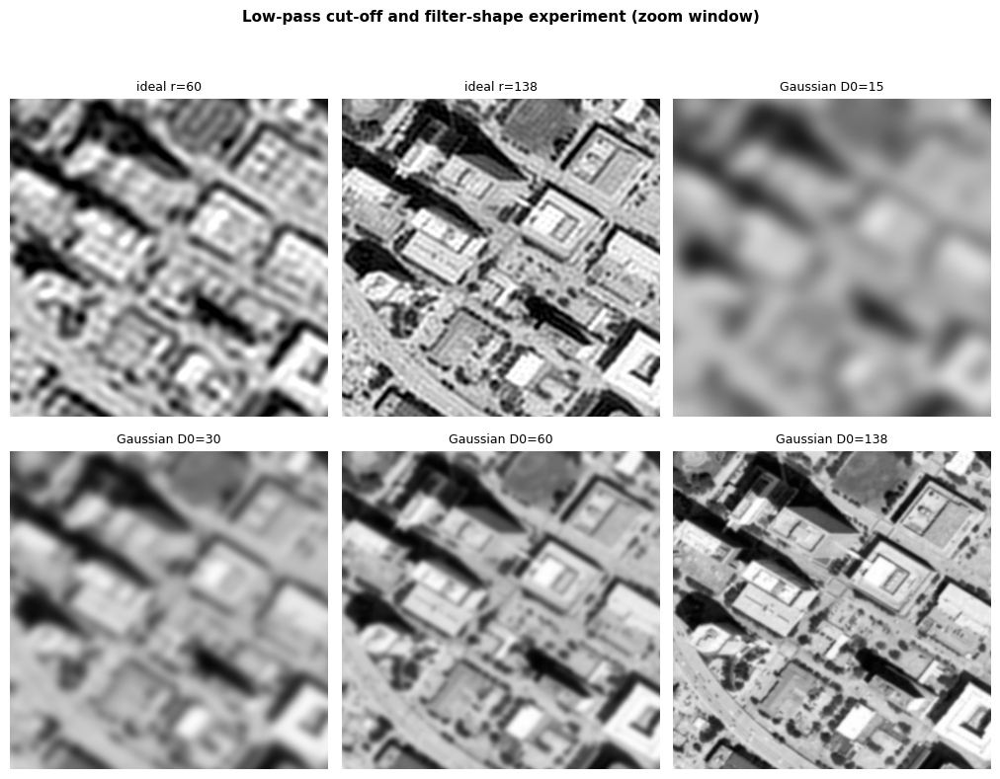

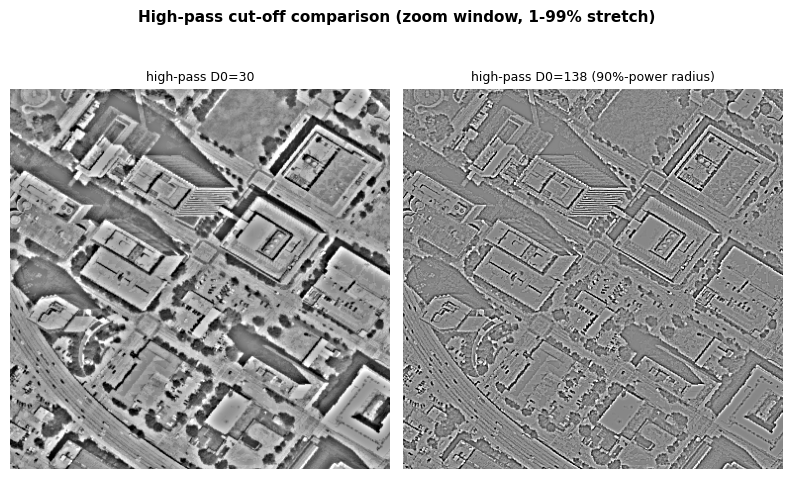

In [14]:
show([clahe_img, lp_img, hp_img],
     ["Input: CLAHE output", f"Output: Gaussian low-pass (D0={D0})\nregion map",
      f"Output: Gaussian high-pass (D0={D0})\nstructure map, 1-99% stretch"],
     suptitle="Frequency-domain filtering: before / after", size=4.2)
show(list(lp_imgs.values()), list(lp_imgs.keys()), suptitle="Low-pass cut-off and filter-shape experiment (zoom window)",
     crop=True, cols=3, size=3.4)
show([hp_img, hp_img_r90], [f"high-pass D0={D0}", f"high-pass D0={r90} (90%-power radius)"],
     suptitle="High-pass cut-off comparison (zoom window, 1-99% stretch)", crop=True, size=4)

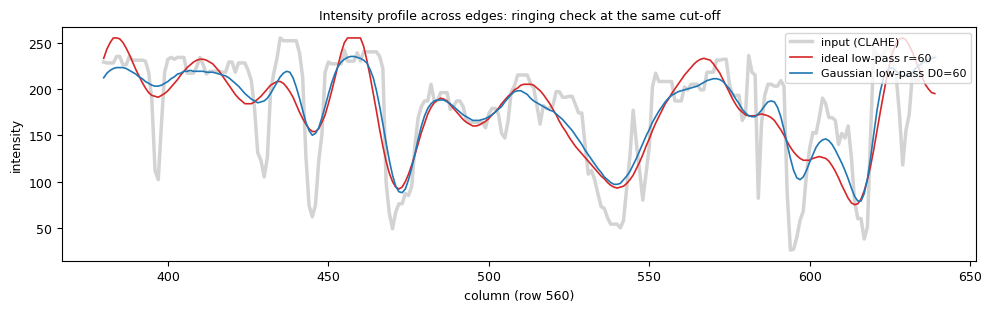

At cut-off 60: ideal removes 32% of local contrast at 16.8 dB; Gaussian removes 41% at 18.3 dB


In [15]:
# Ringing check: one image row crossing building / shadow edges, ideal vs. Gaussian at the same cut-off
row, cols_ = 560, slice(380, 640)
x = np.arange(cols_.start, cols_.stop)
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(x, clahe_img[row, cols_], color="lightgray", lw=2.5, label="input (CLAHE)")
ax.plot(x, lp_imgs["ideal r=60"][row, cols_], color="tab:red", lw=1.2, label="ideal low-pass r=60")
ax.plot(x, lp_imgs["Gaussian D0=60"][row, cols_], color="tab:blue", lw=1.2, label="Gaussian low-pass D0=60")
ax.set_xlabel(f"column (row {row})"); ax.set_ylabel("intensity"); ax.legend(loc="upper right", fontsize=8)
ax.set_title("Intensity profile across edges: ringing check at the same cut-off")
fig.tight_layout(); plt.show()

ft = fft_table.set_index("low-pass filter")
print("At cut-off 60: ideal removes {:.0f}% of local contrast at {:.1f} dB; Gaussian removes {:.0f}% at {:.1f} dB".format(
    ft.loc["ideal r=60", "% local contrast removed"], ft.loc["ideal r=60", "PSNR vs input (dB)"],
    ft.loc["Gaussian D0=60", "% local contrast removed"], ft.loc["Gaussian D0=60", "PSNR vs input (dB)"]))

**Parameter result.** The 90%-power radius (r = 138) turned out to be the wrong criterion for a region map. The Gaussian
filter at $D_0$ = 138 removes only 19% of local contrast, and the output looks almost the same as the input. Its high
PSNR (23.1 dB) only means it changed little. Lowering the cut-off trades PSNR for uniformity: $D_0$ = 60 removes 41%,
$D_0$ = 30 removes 63%, and $D_0$ = 15 removes 81%. The uniformity metric alone would pick $D_0$ = 15. We reject that
setting because neighboring building blocks merge into blobs. The rule we use is therefore **the largest local-contrast
removal before blocks merge**, which selects **Gaussian $D_0$ = 30**. In the zoom window the result is a *soft*
region map: cars, striping and roof texture are gone, and building blocks, the highway corridor and the lawn remain
as separate (but not perfectly flat) regions.

**Ideal vs. Gaussian (ringing).** At the same cut-off of 60, the Gaussian filter removes *more* local contrast than
the ideal filter (41% vs. 32%) yet stays *closer* to the input (18.3 vs. 16.8 dB). The ideal filter's extra error is
therefore not useful smoothing. The intensity profile shows what it is: at columns 383 and 458, where the input is
already at a flat roof top, the ideal filter (red) overshoots by +27 and +25 intensity units and oscillates beside
the edge. That is Gibbs ringing. The Gaussian (blue) is -6 and +5 at those same columns: it overshoots less. (Column
628 is not used as evidence: both filters overshoot there.) In the zoom window, the ideal r = 60 panel shows the
same ringing as stripes parallel to building edges.

**Analysis.**

- *What changed:* the $D_0$ = 30 low-pass output keeps coarse regions (building blocks, lawns, the highway corridor)
  and removes small detail. Its complementary high-pass output, shown with a 1-99% percentile stretch, keeps the
  street grid, building outlines and ramp edges. The high-pass at $D_0$ = 138 shows only fine texture, not the grid.
- *Did it help:* yes. Low-pass and high-pass now actually separate "where the regions are" from "where the
  boundaries are".
- *Unwanted effects:* region boundaries in the low-pass image are soft, about 5 px of blur, so it cannot locate edges
  precisely. Edges come from Canny. Tall buildings' shadows remain as dark regions that could be mistaken for a
  separate class.
- *Decision:* **modify**. Use a Gaussian instead of an ideal mask, and set $D_0$ = 30 by the rule "largest
  local-contrast removal before blocks merge" (not the 90%-power rule). The low-pass output becomes the input for
  region segmentation in Phase 3, and the high-pass output becomes a structure map.

### 3.5 Edge & Corner Detection -- Canny and Harris

**Canny.** In our repo baseline we ran Canny on the sharpened image, with thresholds set by the median-gradient rule
(low = 0.66 x median, high = 1.33 x median of the Sobel gradient magnitude). We compare four settings:

- A: the repo baseline.
- B: the same rule without sharpening.
- C: Gaussian blur (5 x 5, $\sigma$ = 1.4) before Canny.
- D: Gaussian blur plus stricter thresholds (1.0 x / 2.0 x median).

Without ground-truth edges we use objective structure metrics: edge-pixel density, number of connected edge
segments, mean segment length (longer means more continuous outlines), and the share of tiny segments under 10 px,
which are mostly texture speckle rather than real boundaries. **Caveat:** these metrics favor fewer edges by
construction. A setting that drops real but weak edges also scores "better", so they are proxies until we can score
precision and recall against reference outlines (Next Steps).

In [16]:
def median_rule(img, lo=0.66, hi=1.33):
    gx = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)
    gy = cv2.Sobel(img, cv2.CV_64F, 0, 1, ksize=3)
    m = float(np.median(np.hypot(gx, gy)))
    return lo * m, min(255.0, hi * m)

def edge_stats(name, img, lo, hi):
    e = cv2.Canny(img, int(lo), int(hi))
    n, _, stats, _ = cv2.connectedComponentsWithStats((e > 0).astype(np.uint8), connectivity=8)
    sizes = stats[1:, cv2.CC_STAT_AREA]
    return e, {"setting": name.split(":")[0], "low": lo, "high": hi, "edge px %": 100 * np.mean(e > 0),
               "segments": n - 1, "mean length (px)": sizes.mean(),
               "speckle % (<10 px)": 100 * np.mean(sizes < 10)}

smooth = cv2.GaussianBlur(sharp, (5, 5), 1.4)
settings = [("A: sharpened, median rule (repo baseline)", sharp, *median_rule(sharp)),
            ("B: CLAHE (no sharpening), median rule", clahe_img, *median_rule(clahe_img)),
            ("C: sharpened + Gaussian blur, median rule", smooth, *median_rule(smooth)),
            ("D: sharpened + Gaussian blur, 1.0x / 2.0x median", smooth, *median_rule(smooth, 1.0, 2.0))]
canny_imgs, rows = {}, []
for name, img, lo, hi in settings:
    e, r = edge_stats(name, img, lo, hi)
    canny_imgs[name] = e
    rows.append(r)
canny_table = pd.DataFrame(rows)
canny_table

,setting,low,high,edge px %,segments,mean length (px),speckle % (<10 px)
0,A,65.716,132.427,27.580,11999,24.101,69.156
1,B,56.073,112.995,26.140,10582,25.902,65.451
2,C,44.899,90.479,18.630,5546,35.224,44.176
3,D,68.029,136.059,16.104,3703,45.601,31.704


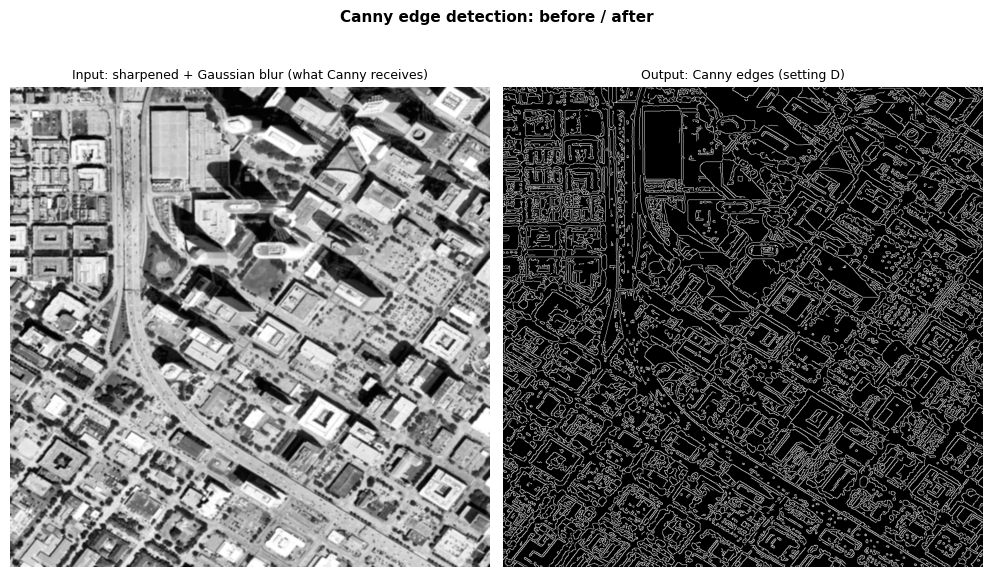

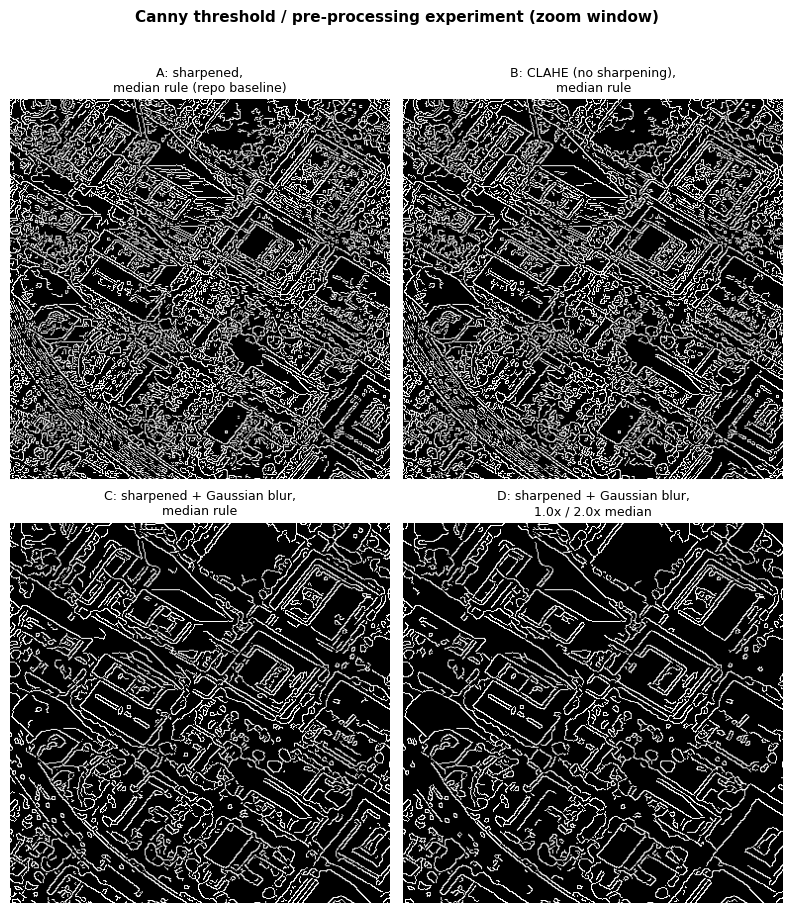

In [17]:
best_canny = canny_imgs["D: sharpened + Gaussian blur, 1.0x / 2.0x median"]
show([smooth, best_canny], ["Input: sharpened + Gaussian blur (what Canny receives)", "Output: Canny edges (setting D)"],
     suptitle="Canny edge detection: before / after", size=5)
show(list(canny_imgs.values()), [k.split(",")[0] + ",\n" + k.split(",", 1)[1].strip() for k in canny_imgs], cols=2,
     size=4, suptitle="Canny threshold / pre-processing experiment (zoom window)", crop=True)

**Parameter result.** The repo baseline (A) marks 27.6% of all pixels as edges. 69% of its segments are shorter than
10 px, and the zoom window looks like dense texture rather than outlines. Removing sharpening (B) barely helps (26.1%).
Most of the clutter comes from fine texture, not the sharpening weight. Blurring first (C) cuts the density to 18.6%
and speckle to 44%. **Setting D worked best**: 16.1% edge pixels, 3,703 segments instead of 11,999, mean segment
length 45.6 px instead of 24.1 px, and only 32% speckle. Building footprints, the highway edges and the ramp curves now
form continuous lines.

**Analysis.**

- *What changed:* the edge map went from a texture map to an outline map.
- *Did it help:* yes. Long, connected building and road boundaries are what a later segmentation step needs.
- *Unwanted effects:* stricter thresholds drop some weak edges, such as low-contrast roof edges and lane lines inside
  shadows. Trees still produce small closed contours.
- *Decision:* **modify**. Use a Gaussian blur followed by Canny with 1.0 x / 2.0 x median thresholds.

**CLAHE clip limit, re-checked downstream.** Section 3.2 found clip 1.5 more balanced than our chosen 2.5. To see
whether that matters for the actual goal, we re-ran the whole chosen chain (CLAHE, sharpen w = 0.05, Gaussian blur,
Canny setting D) with clip 1.5, 2.0 and 2.5.

In [18]:
rows = []
for clip in [1.5, 2.0, 2.5]:
    ch = cv2.createCLAHE(clipLimit=clip, tileGridSize=(8, 8)).apply(stretched)
    sh = np.clip(ch.astype(np.float64) - 0.05 * cv2.Laplacian(ch, cv2.CV_64F, ksize=3), 0, 255).astype(np.uint8)
    sm = cv2.GaussianBlur(sh, (5, 5), 1.4)
    _, r = edge_stats(f"clip {clip}", sm, *median_rule(sm, 1.0, 2.0))
    rows.append(r)
clahe_recheck = pd.DataFrame(rows).drop(columns=["low", "high"])
clahe_recheck

,setting,edge px %,segments,mean length (px),speckle % (<10 px)
0,clip 1.5,15.646,3827,42.870,33.185
1,clip 2.0,15.969,3843,43.573,32.787
2,clip 2.5,16.104,3703,45.601,31.704


**Result.** The edge maps are almost identical: 15.6-16.1% edge pixels and 32-33% speckle for all three clip values.
Clip 2.5 has slightly longer segments (45.6 px vs. 42.9 px at clip 1.5) and the least speckle. The better balance of
clip 1.5 does not carry through to edge quality, so we **keep clip 2.5**.

**Harris corners.** We vary the response threshold (0.01, 0.05 and 0.10 of the maximum response), the sensitivity
$k$ (0.04 vs. 0.06), and the input (sharpened vs. sharpened + blurred). Because each corner covers several pixels, we
count "corner clusters" (connected groups of corner pixels) as an approximate keypoint count.

In [19]:
def harris_overlay(img, k, frac):
    R = cv2.cornerHarris(np.float32(img), blockSize=2, ksize=3, k=k)
    mask = R > frac * R.max()
    n_blobs = cv2.connectedComponents(cv2.dilate(mask.astype(np.uint8), None), connectivity=8)[0] - 1
    ov = color.copy()
    ov[cv2.dilate(mask.astype(np.uint8), None) == 1] = (0, 0, 255)
    return ov, {"input": "sharpened" if img is sharp else "sharpened + Gaussian blur", "k": k, "threshold (x max R)": frac,
                "corner pixels": int(mask.sum()), "corner clusters (~keypoints)": n_blobs}

harris_imgs, rows = {}, []
for img, k, frac in [(sharp, 0.04, 0.01), (sharp, 0.04, 0.05), (sharp, 0.04, 0.10), (sharp, 0.06, 0.05), (smooth, 0.04, 0.05)]:
    ov, r = harris_overlay(img, k, frac)
    harris_imgs[f"{r['input']}\nk={k}, thr={frac} x max"] = ov
    rows.append(r)
harris_table = pd.DataFrame(rows)
harris_table

,input,k,threshold (x max R),corner pixels,corner clusters (~keypoints)
0,sharpened,0.04,0.01,61967,4075
1,sharpened,0.04,0.05,15884,3466
2,sharpened,0.04,0.10,6143,2215
3,sharpened,0.06,0.05,13250,3281
4,sharpened + Gaussian blur,0.04,0.05,9151,1959


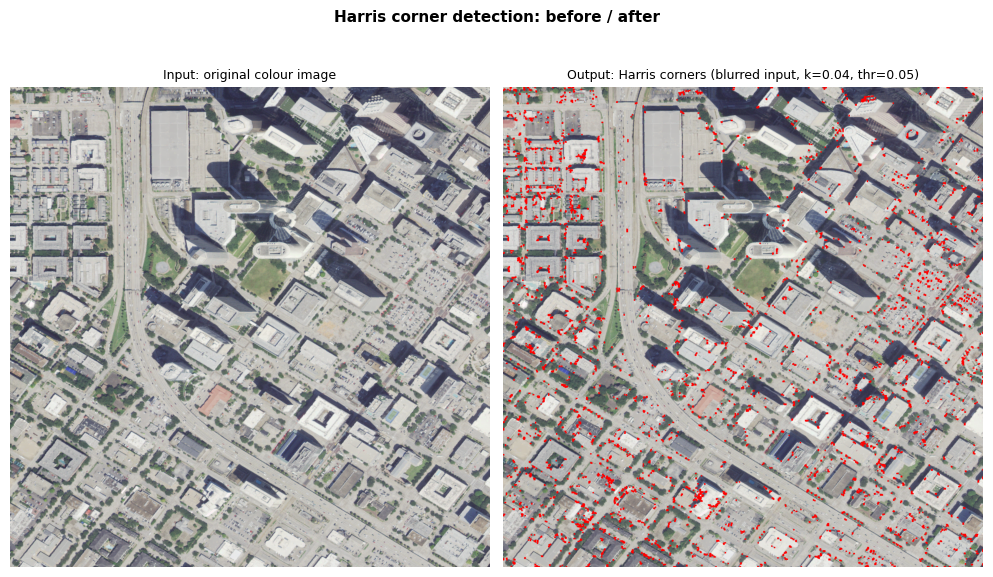

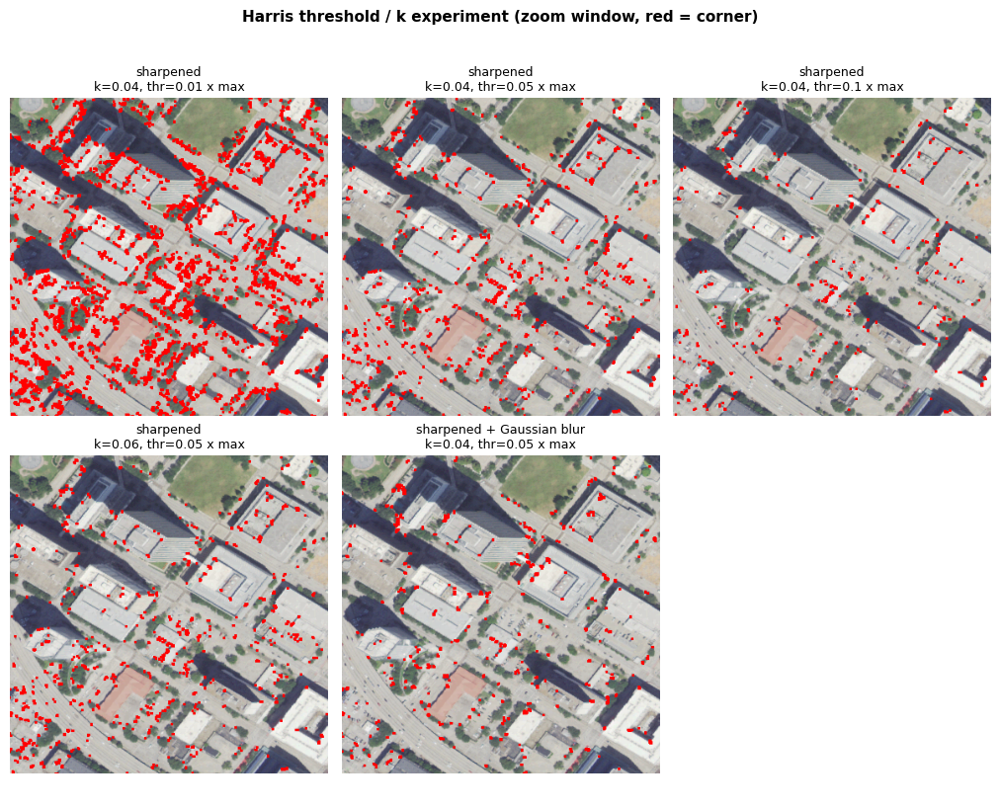

In [20]:
show([color, harris_imgs["sharpened + Gaussian blur\nk=0.04, thr=0.05 x max"]],
     ["Input: original colour image", "Output: Harris corners (blurred input, k=0.04, thr=0.05)"],
     suptitle="Harris corner detection: before / after", size=5)
show(list(harris_imgs.values()), list(harris_imgs.keys()), cols=3, size=3.4,
     suptitle="Harris threshold / k experiment (zoom window, red = corner)", crop=True)

**Parameter result.** The repo-baseline threshold (0.01 x max) flags 62k pixels in 4,075 clusters. The zoom window is covered
in red, including tree canopy and pavement texture. Raising the threshold to 0.05 cuts this to 15.9k pixels and 3,466
clusters, and 0.10 cuts it to 2,215 clusters but starts missing real building corners. Changing $k$ from 0.04 to 0.06
has a smaller effect (3,466 to 3,281 clusters). **Blurred input with threshold 0.05 worked best**: 1,959 clusters,
concentrated on building corners, roof structures and road junctions, with far fewer hits in tree canopy.

**Analysis.**

- *What changed:* corners are now sparse, interpretable keypoints instead of a texture response.
- *Did it help:* yes. The remaining corners match real structure, which is what we wanted as a proxy for structural
  complexity.
- *Unwanted effects:* tree crowns and cars still produce some corners, and a few corners on low-contrast roofs are
  lost.
- *Decision:* **modify**. Run Harris on the blurred image with threshold 0.05 x max and $k$ = 0.04. Add non-maximum
  suppression in Phase 3 to get exactly one point per corner.

## 4. Preliminary Evaluation

We do not have pixel-level ground truth for this scene yet, so each stage is scored with a metric that matches its
purpose: reaching a target mean intensity, balanced contrast gain, PSNR against a clean reference, clipped-pixel
fraction, region uniformity, and edge continuity and speckle. The table compares a baseline with the current
choice. The "baseline (source)" column says whether each baseline comes from the proposal, our repo run, or is
simply the unprocessed or worst-tested case. The figure shows the intermediate result of each stage on the full
frame.

In [21]:
g = gamma_table.set_index("gamma")
c = clahe_table.set_index("method")
m = median_table.set_index("filter")
s = sharpen_table.set_index("weight")
f = fft_table.set_index("low-pass filter")
e = canny_table.set_index("setting")
hr = harris_table
summary = pd.DataFrame([
    ["Gamma", "shadow-quartile mean (target 110)", f"{g.iloc[0]['shadow mean']:.1f} (no gamma)", f"{g.loc[gamma_auto, 'shadow mean']:.1f} (gamma={gamma_auto:.3f})"],
    ["CLAHE", "dark/bright gain balance (1.0 = even)", f"{c.loc['global HE', 'balance (dark/bright)']:.2f} (global HE)", f"{c.loc['CLAHE clip=2.5, tile=8', 'balance (dark/bright)']:.2f} (clip 2.5, tile 8)"],
    ["Median", "PSNR vs clean reference (dB)", f"{m.loc['noisy input', 'PSNR vs clean (dB)']:.1f} (noisy)", f"{m.loc['median k=3', 'PSNR vs clean (dB)']:.1f} (k=3)"],
    ["Sharpening", "% clipped pixels (budget 5%)", f"{s.loc[0.6, '% pixels clipped (0/255)']:.1f} (w=0.6)", f"{s.loc[0.05, '% pixels clipped (0/255)']:.1f} (w=0.05)"],
    ["FFT low-pass", "% local contrast removed (region uniformity)", f"{f.loc['ideal r=60', '% local contrast removed']:.0f} (ideal r=60, proposal)", f"{f.loc[f'Gaussian D0={D0}', '% local contrast removed']:.0f} (Gaussian D0={D0})"],
    ["Canny", "edge px % / speckle %",
     f"{e.iloc[0]['edge px %']:.1f} / {e.iloc[0]['speckle % (<10 px)']:.0f} (setting A, repo)",
     f"{e.iloc[3]['edge px %']:.1f} / {e.iloc[3]['speckle % (<10 px)']:.0f} (setting D)"],
    ["Harris", "corner clusters", f"{hr.iloc[0]['corner clusters (~keypoints)']} (thr 0.01, repo)", f"{hr.iloc[4]['corner clusters (~keypoints)']} (blurred, thr 0.05)"],
], columns=["stage", "metric", "baseline (source)", "current choice"])
summary

,stage,metric,baseline (source),current choice
0,Gamma,shadow-quartile mean (target 110),89.5 (no gamma),109.1 (gamma=1.245)
1,CLAHE,dark/bright gain balance (1.0 = even),0.66 (global HE),"0.87 (clip 2.5, tile 8)"
2,Median,PSNR vs clean reference (dB),21.8 (noisy),26.2 (k=3)
3,Sharpening,% clipped pixels (budget 5%),35.8 (w=0.6),4.6 (w=0.05)
4,FFT low-pass,% local contrast removed (region uniformity),"32 (ideal r=60, proposal)",63 (Gaussian D0=30)
5,Canny,edge px % / speckle %,"27.6 / 69 (setting A, repo)",16.1 / 32 (setting D)
6,Harris,corner clusters,"4075 (thr 0.01, repo)","1959 (blurred, thr 0.05)"


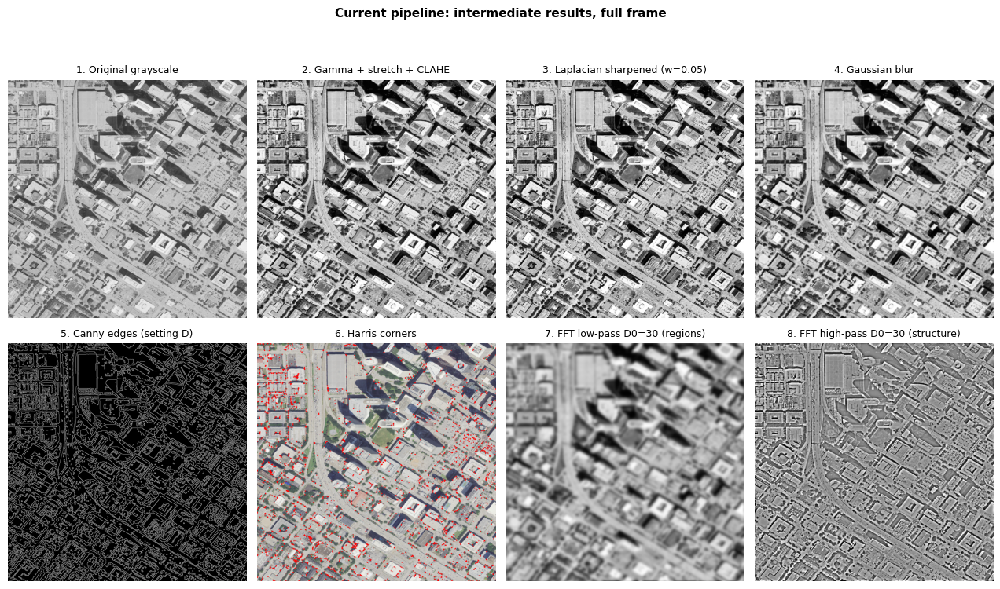

In [22]:
show([gray, clahe_img, sharp, smooth, best_canny, harris_imgs["sharpened + Gaussian blur\nk=0.04, thr=0.05 x max"], lp_img, hp_img],
     ["1. Original grayscale", "2. Gamma + stretch + CLAHE", "3. Laplacian sharpened (w=0.05)", "4. Gaussian blur",
      "5. Canny edges (setting D)", "6. Harris corners", f"7. FFT low-pass D0={D0} (regions)", f"8. FFT high-pass D0={D0} (structure)"],
     cols=4, size=3.2, suptitle="Current pipeline: intermediate results, full frame")

**Summary.** Every stage now has a measurable reason for its parameters:

- Gamma reaches its shadow target within 1%.
- CLAHE is measurably more balanced than global HE (0.87 vs. 0.66), and its clip limit was confirmed downstream.
- The median filter recovers 4.4 dB on impulse noise but is not needed on this clean image.
- Sharpening stays within the 5% clipping budget.
- The Gaussian low-pass at $D_0$ = 30 removes 63% of local contrast, a real region map, without the ringing of the
  ideal filter.

The largest improvements over our earlier settings are in edge detection (edge density 27.6% to 16.1%, speckle 69%
to 32%) and in the FFT stage, which now actually separates regions from structure. The main limitation is that
these are *proxy* metrics. In particular, the edge metrics favor fewer edges. In Phase 3 we plan to score edges
against reference building and road outlines (see Next Steps).

## 5. Updated Pipeline

Current planned sequence. Changes from the proposal or the repo baseline are in **bold**.

1. Load the NAIP 1 m RGB crop and convert it to grayscale.
2. Gamma correction with **$\gamma$ solved from the shadow-quartile mean** (1.245 for this scene; the proposal used a fixed 1.4).
3. Linear contrast stretch, 2nd/98th percentile clip.
4. CLAHE, clip 2.5 and 8 x 8 tiles (unchanged; clip 1.5 and 2.0 tested downstream with no gain).
5. **Median filter, k = 3, only when impulse noise or speckle is present** (the proposal used k = 5; removed from the default chain for this clean scene).
6. Laplacian sharpening, **weight 0.05** (largest weight within the 5% clipping budget), for the enhanced visual output.
7. **Gaussian blur (5 x 5, $\sigma$ = 1.4) before feature extraction** (new step).
8. Canny edges with **1.0 x / 2.0 x median-gradient thresholds** (repo baseline: 0.66 x / 1.33 x on the unblurred image).
9. Harris corners **on the blurred image, threshold 0.05 x max response**, k = 0.04 (repo baseline: 0.01 x max).

Frequency-domain branch, taken from the CLAHE output after step 4:

- **Gaussian low-pass, $D_0$ = 30** (the proposal used an ideal r = 60). This gives the region map for land-cover
  segmentation.
- **Gaussian high-pass at the same $D_0$**, percentile-stretched for display. This gives the structure map (street
  grid, building outlines).

```
RGB -> gray -> gamma -> stretch -> CLAHE
                                     |
        +----------------------------+-------------+
        |                                          |
  sharpen (display)                   FFT Gaussian D0 = 30
        |                               low-pass  -> regions
  Gaussian blur                         high-pass -> structure
        |
  Canny edges + Harris corners
```

## 6. Next Steps

**What still needs to be completed**

- A land-cover separation step that combines the outputs: thresholding or region growing on the low-pass image, plus
  simple color indices from the RGB bands, such as excess green ($2G - R - B$) for vegetation. This would produce
  approximate road, building and vegetation maps; at the moment the pipeline only works in grayscale.
- The **water class**. This crop has no open water, so water separation is untested. We will add a second NAIP crop
  that includes Buffalo Bayou (just north of the current scene). This NAIP product is RGB only (no NIR), and the
  bayou water in that strip is brown, so a simple RGB water index may fail. If it does, we will fall back on the
  low-pass region map plus hue/saturation or a hand-labeled mask rather than assuming an index will work.
- An objective accuracy check against reference data. We plan to compare Canny edges with OpenStreetMap building and
  road outlines for the same bounding box, reporting edge precision and recall, or to hand-label a small patch. This
  will also replace our proxy edge metrics, which favor fewer edges by construction.
- Test whether blurring the CLAHE output directly, without sharpening, gives equally clean Canny edges.
- Non-maximum suppression for Harris, so each corner is a single keypoint.
- (Optional) Deep-learning extension. A COCO-pretrained YOLOv8n returned no detections on this 1 m scene in our
  repo run, because cars are only about 4 to 5 px wide. We plan to try an aerial-trained model (YOLOv8-OBB
  trained on DOTA) on tiled, upsampled patches.

**Problems and challenges encountered**

- The real NAIP crop has almost no impulse noise, so the median filter could only be tested with synthetic noise.
  It turned out to be unnecessary for this scene.
- Without ground truth, we had to design proxy metrics for each stage.
- Our first edge detector setting was far too dense (27.6% of pixels). We traced this to texture amplification by
  the enhancement stages and fixed it with blurring and stricter thresholds.
- Our first FFT cut-off rule (90% of AC power) produced a "low-pass" image that barely differed from the input, and
  PSNR made it look good. We added a region-uniformity metric to choose the cut-off.
- Gamma brightens shadows but compresses highlights, so it must be paired with stretching or CLAHE.
- During development we fixed an inverted gamma formula and an FFT cut-off search that always returned r = 0 because
  the DC term was included.

**Planned improvements before Phase 3**

- Test the pipeline on a second NAIP scene (the Buffalo Bayou crop above, and possibly a residential area) to check
  that the self-tuning parameters and the $D_0$ = 30 cut-off generalize.
- Try an FFT band-pass filter, as mentioned in the proposal, to isolate the street-grid frequency band.
- Combine the edge, corner and region outputs into one land-cover overlay for the final report.